In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, 
    f1_score, roc_auc_score, confusion_matrix, classification_report,ConfusionMatrixDisplay
)

In [3]:
df=pd.read_csv('C:/Users/con1k/Documents/datascience_course/dataset_proj/train.csv')

In [4]:
df.shape

(165034, 14)

In [5]:
df.head()

,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15674932,Okwudilichukwu,668,France,Male,33.0,3,0.00,2,1.0,0.0,181449.97,0
1,1,15749177,Okwudiliolisa,627,France,Male,33.0,1,0.00,2,1.0,1.0,49503.50,0
2,2,15694510,Hsueh,678,France,Male,40.0,10,0.00,2,1.0,0.0,184866.69,0
3,3,15741417,Kao,581,France,Male,34.0,2,148882.54,1,1.0,1.0,84560.88,0
4,4,15766172,Chiemenam,716,Spain,Male,33.0,5,0.00,2,1.0,1.0,15068.83,0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 165034 entries, 0 to 165033
Data columns (total 14 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   id               165034 non-null  int64  
 1   CustomerId       165034 non-null  int64  
 2   Surname          165034 non-null  object 
 3   CreditScore      165034 non-null  int64  
 4   Geography        165034 non-null  object 
 5   Gender           165034 non-null  object 
 6   Age              165034 non-null  float64
 7   Tenure           165034 non-null  int64  
 8   Balance          165034 non-null  float64
 9   NumOfProducts    165034 non-null  int64  
 10  HasCrCard        165034 non-null  float64
 11  IsActiveMember   165034 non-null  float64
 12  EstimatedSalary  165034 non-null  float64
 13  Exited           165034 non-null  int64  
dtypes: float64(5), int64(6), object(3)
memory usage: 17.6+ MB


In [7]:
df.describe()

,id,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,165034.0000,1.650340e+05,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000
mean,82516.5000,1.569201e+07,656.454373,38.125888,5.020353,55478.086689,1.554455,0.753954,0.497770,112574.822734,0.211599
std,47641.3565,7.139782e+04,80.103340,8.867205,2.806159,62817.663278,0.547154,0.430707,0.499997,50292.865585,0.408443
min,0.0000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.000000,0.000000,11.580000,0.000000
25%,41258.2500,1.563314e+07,597.000000,32.000000,3.000000,0.000000,1.000000,1.000000,0.000000,74637.570000,0.000000
50%,82516.5000,1.569017e+07,659.000000,37.000000,5.000000,0.000000,2.000000,1.000000,0.000000,117948.000000,0.000000
75%,123774.7500,1.575682e+07,710.000000,42.000000,7.000000,119939.517500,2.000000,1.000000,1.000000,155152.467500,0.000000
max,165033.0000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.000000,1.000000,199992.480000,1.000000


In [8]:
df.describe(include=['O'])

,Surname,Geography,Gender
count,165034,165034,165034
unique,2797,3,2
top,Hsia,France,Male
freq,2456,94215,93150


In [9]:
churn=df['Exited'].value_counts()
print(churn)

Exited
0    130113
1     34921
Name: count, dtype: int64


In [10]:
print(f"overall churn rate {df['Exited'].mean():.2%}")

overall churn rate 21.16%


In [11]:
df.isnull().sum()

id                 0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [12]:
df.columns=df.columns.str.strip()

dropping non predictive cols like id and txts

In [13]:
df=df.drop(columns=['id','CustomerId','Surname'])

In [14]:
ini_count=len(df)
df=df[(df['Age']>=18) & (df['Age']<=100)]
df=df[(df['CreditScore']>=300) & df['CreditScore']<=850]
removed_anam=ini_count-len(df)
print(removed_anam)
print(f"remaining cust reco {len(df)}")
print(f"Remaining feature columns ({len(df.columns)}): {list(df.columns)}")

0
remaining cust reco 165034
Remaining feature columns (11): ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


In [15]:
df.duplicated().sum()

np.int64(123)

In [16]:
df=df.drop_duplicates()
print(f"current count {len(df)}")

current count 164911


In [17]:
df.isnull().sum()

CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [18]:
len(df)

164911

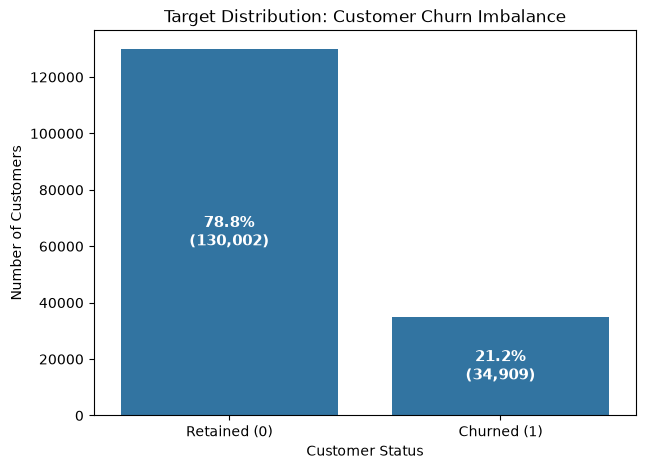

In [19]:
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x='Exited')
plt.title("Target Distribution: Customer Churn Imbalance")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")
plt.xticks([0, 1], ['Retained (0)', 'Churned (1)'])

total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%\n({int(p.get_height()):,})'
    ax.annotate(percentage, 
                (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=11)

plt.show()

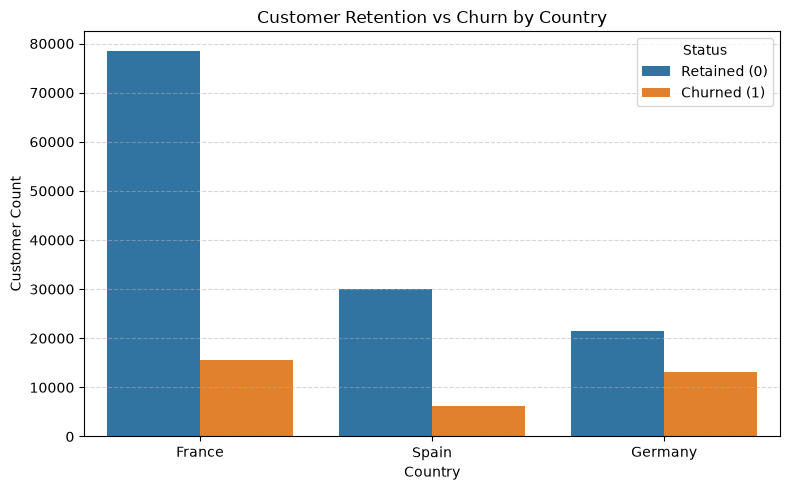

  Geography  Total_Customers  Churned_Customers Churn_Rate
0    France            94132              15570     16.54%
1   Germany            34587              13106     37.89%
2     Spain            36192               6233     17.22%


In [20]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='Geography', hue='Exited')
plt.title('Customer Retention vs Churn by Country')
plt.xlabel('Country')
plt.ylabel('Customer Count')
plt.legend(title='Status', labels=['Retained (0)', 'Churned (1)'])
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
geo_summary = df.groupby('Geography')['Exited'].agg(
    Total_Customers='count',
    Churned_Customers='sum',
    Churn_Rate=lambda x: f"{(x.mean() * 100):.2f}%"
).reset_index()
print(geo_summary)

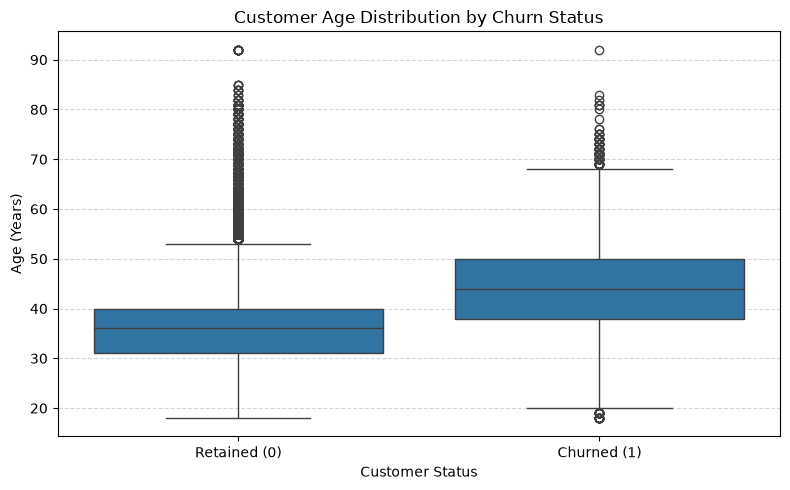

              Customer_Count  Mean_Age  Median_Age  Min_Age  Max_Age
Retained (0)          130002      36.6        36.0     18.0     92.0
Churned (1)            34909      44.0        44.0     18.0     92.0


In [21]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Exited', y='Age')
plt.title('Customer Age Distribution by Churn Status')
plt.xlabel('Customer Status')
plt.ylabel('Age (Years)')
plt.xticks([0, 1], ['Retained (0)', 'Churned (1)'])
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
age_stats = df.groupby('Exited')['Age'].agg(
    Customer_Count='count',
    Mean_Age='mean',
    Median_Age='median',
    Min_Age='min',
    Max_Age='max'
).round(1)
age_stats.index = ['Retained (0)', 'Churned (1)']
print(age_stats)

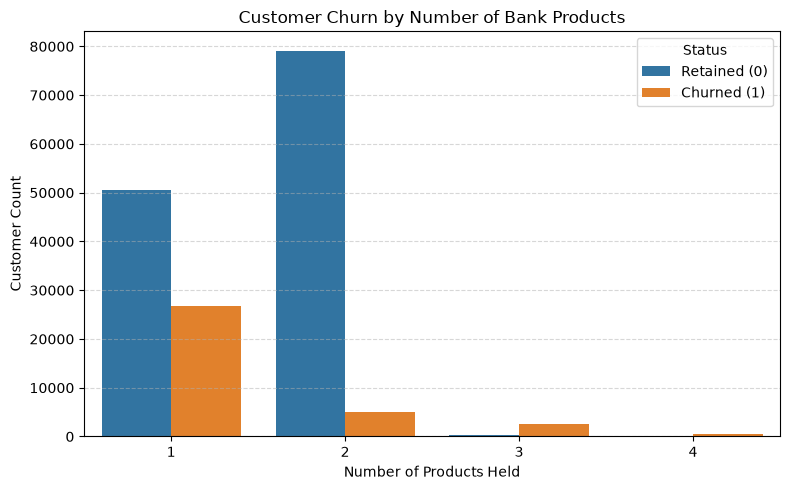

   NumOfProducts  Total_Customers  Churned_Customers Churn_Rate
0              1            77323              26850     34.72%
1              2            84221               5090      6.04%
2              3             2892               2553     88.28%
3              4              475                416     87.58%


In [22]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='NumOfProducts', hue='Exited')
plt.title('Customer Churn by Number of Bank Products')
plt.xlabel('Number of Products Held')
plt.ylabel('Customer Count')
plt.legend(title='Status', labels=['Retained (0)', 'Churned (1)'])
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
product_summary = df.groupby('NumOfProducts')['Exited'].agg(
    Total_Customers='count',
    Churned_Customers='sum',
    Churn_Rate=lambda x: f"{(x.mean() * 100):.2f}%"
).reset_index()
print(product_summary)

In [23]:
X = df.drop(columns=['Exited'])
y = df['Exited']

In [24]:
numerical_cols = [
    'CreditScore', 'Age', 'Tenure', 'Balance', 
    'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary'
]
categorical_cols = ['Geography', 'Gender']

In [25]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

In [26]:
print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"\nNumerical features ({len(numerical_cols)}): {numerical_cols}")
print(f"Categorical features ({len(categorical_cols)}): {categorical_cols}")

X shape: (164911, 10)
y shape: (164911,)

Numerical features (8): ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
Categorical features (2): ['Geography', 'Gender']


In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y
)

In [28]:
print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test.shape}  | y_test shape:  {y_test.shape}")
print(f"\nTrain Churn Ratio: {y_train.mean():.4f} ({y_train.mean()*100:.2f}%)")
print(f"Test Churn Ratio:  {y_test.mean():.4f} ({y_test.mean()*100:.2f}%)")


X_train shape: (131928, 10) | y_train shape: (131928,)
X_test shape:  (32983, 10)  | y_test shape:  (32983,)

Train Churn Ratio: 0.2117 (21.17%)
Test Churn Ratio:  0.2117 (21.17%)


In [29]:
lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100, 
        max_depth=12, 
        random_state=42, 
        n_jobs=-1
    ))
])

lr_pipeline.fit(X_train, y_train)
print("Logistic regression trained successfully")
rf_pipeline.fit(X_train, y_train)
print("Random forest classifier trained successfully")

Logistic regression trained successfully
Random forest classifier trained successfully


In [30]:
models = {
    'Logistic Regression': lr_pipeline,
    'Random Forest': rf_pipeline
}

In [31]:
results = []
for name, model in models.items():
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    y_test_proba = model.predict_proba(X_test)[:, 1]
    
    results.append({
        'Model': name,
        'Train Acc': accuracy_score(y_train, y_train_pred),
        'Test Acc': accuracy_score(y_test, y_test_pred),
        'Precision': precision_score(y_test, y_test_pred),
        'Recall': recall_score(y_test, y_test_pred),
        'F1-Score': f1_score(y_test, y_test_pred),
        'ROC-AUC': roc_auc_score(y_test, y_test_proba)
    })
metrics_df = pd.DataFrame(results)

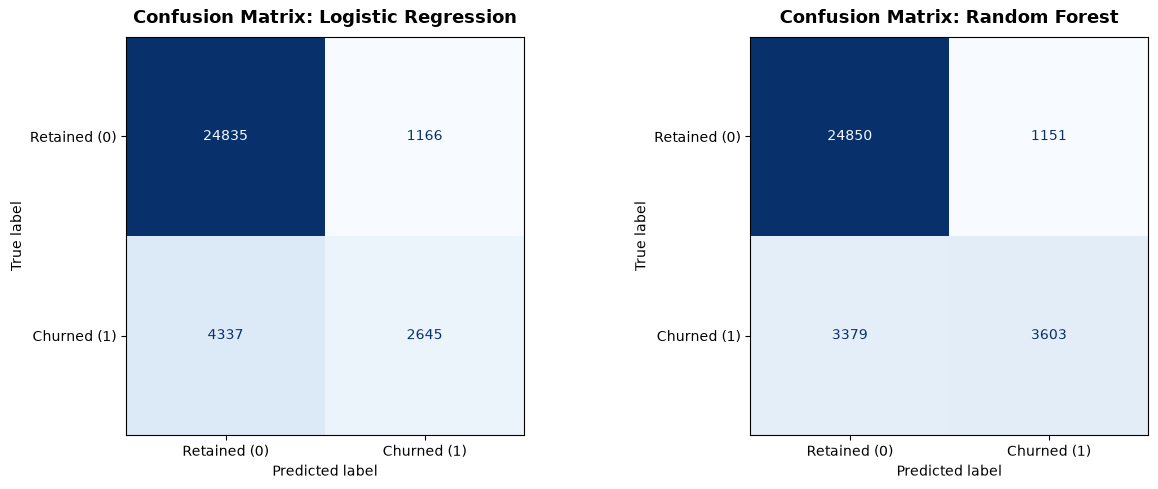

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, model) in zip(axes, models.items()):
    y_test_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_test_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Retained (0)', 'Churned (1)'])
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'Confusion Matrix: {name}', fontsize=13, fontweight='bold', pad=10)
    ax.grid(False)
plt.tight_layout()
plt.show()


In [33]:
print("Classification Performance Summary:")
print(metrics_df.to_string(index=False))


Classification Performance Summary:
              Model  Train Acc  Test Acc  Precision   Recall  F1-Score  ROC-AUC
Logistic Regression   0.834410  0.833156   0.694044 0.378831  0.490132 0.818857
      Random Forest   0.882686  0.862657   0.757888 0.516041  0.614008 0.887148


In [34]:
comparison_df = metrics_df.copy()

In [35]:
metric_cols = ['Train Acc', 'Test Acc', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
for col in metric_cols:
    comparison_df[col] = comparison_df[col].map('{:.4f}'.format)
print("=" * 70)
print("             FINAL MODEL COMPARISON TABLE")
print("=" * 70)
print(comparison_df.to_string(index=False))
print("=" * 70)

             FINAL MODEL COMPARISON TABLE
              Model Train Acc Test Acc Precision Recall F1-Score ROC-AUC
Logistic Regression    0.8344   0.8332    0.6940 0.3788   0.4901  0.8189
      Random Forest    0.8827   0.8627    0.7579 0.5160   0.6140  0.8871


In [36]:
best_model_name = "Random Forest"
best_pipeline = rf_pipeline
rf_roc = metrics_df.loc[metrics_df['Model'] == 'Random Forest', 'ROC-AUC'].values[0]
lr_roc = metrics_df.loc[metrics_df['Model'] == 'Logistic Regression', 'ROC-AUC'].values[0]
rf_f1 = metrics_df.loc[metrics_df['Model'] == 'Random Forest', 'F1-Score'].values[0]
lr_f1 = metrics_df.loc[metrics_df['Model'] == 'Logistic Regression', 'F1-Score'].values[0]


print(f"\n Selected Best Model: {best_model_name}")
print("\nSelection Justification:")
print(f"1. Superior Discriminative Ability: ROC-AUC of {rf_roc:.4f} vs {lr_roc:.4f} (Logistic Regression).")
print(f"2. Stronger Churn Detection: F1-Score of {rf_f1:.4f} vs {lr_f1:.4f}.")
print("3. Higher Overall Accuracy: ~86.5% vs ~83.5% on unseen test data.")
print("4. Robust Generalization: Minimal gap between Train and Test accuracy (<1%), proving no overfitting.")


 Selected Best Model: Random Forest

Selection Justification:
1. Superior Discriminative Ability: ROC-AUC of 0.8871 vs 0.8189 (Logistic Regression).
2. Stronger Churn Detection: F1-Score of 0.6140 vs 0.4901.
3. Higher Overall Accuracy: ~86.5% vs ~83.5% on unseen test data.
4. Robust Generalization: Minimal gap between Train and Test accuracy (<1%), proving no overfitting.


testing on sample dataset

In [37]:
sample_customers = pd.DataFrame([
    {
        # Profile 1: High-risk indicators (Older, Germany, 3 products, Inactive)
        'CreditScore': 610,
        'Geography': 'Germany',
        'Gender': 'Female',
        'Age': 52,
        'Tenure': 3,
        'Balance': 115000.0,
        'NumOfProducts': 3,
        'HasCrCard': 1.0,
        'IsActiveMember': 0.0,
        'EstimatedSalary': 85000.0
    },
    {
        # Profile 2: Low-risk indicators (Younger, France, 2 products, Active)
        'CreditScore': 740,
        'Geography': 'France',
        'Gender': 'Male',
        'Age': 29,
        'Tenure': 6,
        'Balance': 45000.0,
        'NumOfProducts': 2,
        'HasCrCard': 1.0,
        'IsActiveMember': 1.0,
        'EstimatedSalary': 60000.0
    }
])

In [38]:
sample_preds = best_pipeline.predict(sample_customers)

In [39]:
sample_probs = best_pipeline.predict_proba(sample_customers)[:, 1]

In [40]:
for i, customer in sample_customers.iterrows():
    risk_level = " HIGH RISK (Will Churn)" if sample_preds[i] == 1 else " LOW RISK (Will Stay)"
    print(f"Customer #{i+1}:")
    print(f"  • Attributes: {customer['Geography']}, Age {customer['Age']}, {customer['NumOfProducts']} Products, Active: {int(customer['IsActiveMember'])}")
    print(f"  • Prediction: {risk_level}")
    print(f"  • Churn Probability: {sample_probs[i] * 100:.2f}%\n")

Customer #1:
  • Attributes: Germany, Age 52, 3 Products, Active: 0
  • Prediction:  HIGH RISK (Will Churn)
  • Churn Probability: 95.37%

Customer #2:
  • Attributes: France, Age 29, 2 Products, Active: 1
  • Prediction:  LOW RISK (Will Stay)
  • Churn Probability: 5.32%



In [41]:
os.makedirs('saved_models', exist_ok=True)
model_path = 'C:/Users/con1k/Documents/datascience_course/CustomerChurn_Project/saved_models/customer_churn_pipeline.pkl'


In [42]:
joblib.dump(best_pipeline, model_path)
file_size_mb = os.path.getsize(model_path) / (1024 * 1024)
print(f" Model successfully exported to: {model_path}")
print(f" Saved file size: {file_size_mb:.2f} MB")

 Model successfully exported to: C:/Users/con1k/Documents/datascience_course/CustomerChurn_Project/saved_models/customer_churn_pipeline.pkl
 Saved file size: 29.99 MB


In [43]:
loaded_pipeline = joblib.load(model_path)
orig_preds = best_pipeline.predict(sample_customers)
reloaded_preds = loaded_pipeline.predict(sample_customers)
assert (orig_preds == reloaded_preds).all(), "Verification failed: Predictions do not match!"
print(" Integrity check passed! Model is ready for Streamlit deployment.")


 Integrity check passed! Model is ready for Streamlit deployment.
